<a href="https://colab.research.google.com/github/ensogma/CS-103-Autumn/blob/main/Attention_and_transformers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

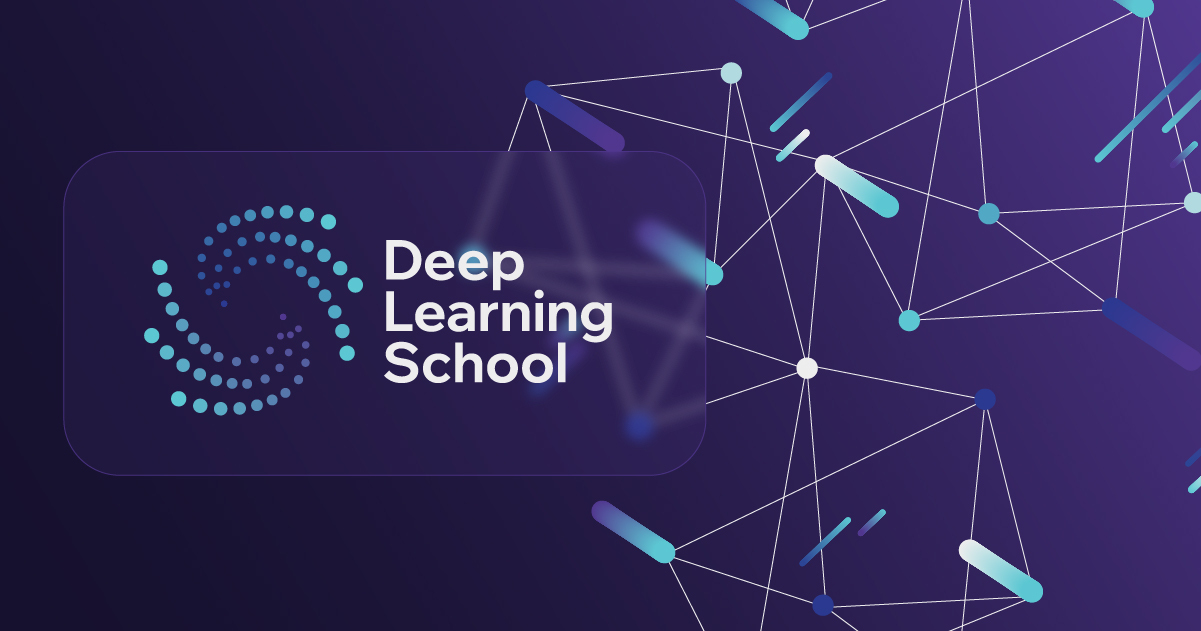

<h3 style="text-align: center;"><b>Школа глубокого обучения ФПМИ МФТИ</b></h3>

<h1 style="text-align: center;"><b>Домашнее задание по теме "Механизм внимания.</b></h1>


Это домашнее задание проходит в формате peer-review. Это означает, что его будут проверять ваши однокурсники. Поэтому пишите разборчивый код, добавляйте комментарии и пишите выводы после проделанной работы.

В этом задании вы будете решать задачу классификации математических задач по темам (многоклассовая классификация) с помощью Transformer.

В качестве датасета возьмем датасет математических задач по разным темам. Нам необходим следующий файл:

[Файл с классами](https://docs.google.com/spreadsheets/d/13YIbphbWc62sfa-bCh8MLQWKizaXbQK9/edit?usp=drive_link&ouid=104379615679964018037&rtpof=true&sd=true)

**Hint:** не перезаписывайте модели, которые вы получите на каждом из этапов этого дз. Они ещё понадобятся.

### Задание 1 (2 балла)

Напишите кастомный класс для модели трансформера для задачи классификации, использующей в качествке backbone какую-то из моделей huggingface.

Т.е. конструктор класса должен принимать на вход название модели и подгружать её из huggingface, а затем использовать в качестве backbone (достаточно возможности использовать в качестве backbone те модели, которые упомянуты в последующих пунктах)

In [1]:
!pip install -q transformers datasets evaluate accelerate scikit-learn seaborn matplotlib

In [2]:
import copy
from typing import Dict, List
import evaluate
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from datasets import Dataset
from torch.optim import AdamW
from torch.utils.data import DataLoader
from tqdm.auto import tqdm
from transformers import AutoConfig, AutoModel, AutoTokenizer

In [3]:
class TransformerClassificationModel(nn.Module):

    def __init__(self, base_transformer_model: str, num_labels: int):
        super().__init__()
        self.config = AutoConfig.from_pretrained(
            base_transformer_model, output_attentions=True
        )
        self.backbone = AutoModel.from_pretrained(
            base_transformer_model, config=self.config
        )

        self.hidden_size = self.config.hidden_size
        self.dropout = nn.Dropout(0.1)
        self.classifier = nn.Linear(self.hidden_size, num_labels)

    def forward(
        self,
        input_ids,
        attention_mask,
        token_type_ids=None,
        labels=None,
    ) -> Dict[str, torch.Tensor]:
        kwargs = {"input_ids": input_ids, "attention_mask": attention_mask}

        if (
            token_type_ids is not None
            and "token_type_ids" in self.backbone.forward.__code__.co_varnames
        ):
            kwargs["token_type_ids"] = token_type_ids

        outputs = self.backbone(**kwargs)

        cls_output = outputs.last_hidden_state[:, 0, :]
        cls_output = self.dropout(cls_output)
        logits = self.classifier(cls_output)

        outputs_dict = {"logits": logits}
        if hasattr(outputs, "attentions"):
            outputs_dict["attentions"] = outputs.attentions

        if labels is not None:
            loss_fct = nn.CrossEntropyLoss()
            loss = loss_fct(logits.view(-1, num_labels), labels.view(-1))
            outputs_dict["loss"] = loss

        return outputs_dict


In [5]:

df = pd.read_csv("/content/data_problems_translated.csv")

df["label"] = df["topic"].astype("category").cat.codes
num_labels = df["label"].nunique()

label_map = dict(enumerate(df["topic"].astype("category").cat.categories))

train_df = df.sample(frac=0.8, random_state=42)
val_df = df.drop(train_df.index)

train_dataset = Dataset.from_pandas(train_df.reset_index(drop=True))
val_dataset = Dataset.from_pandas(val_df.reset_index(drop=True))

### Задание 2 (1 балл)

Напишите функцию заморозки backbone у модели (если необходимо, возвращайте из функции модель)

In [6]:
def freeze_backbone_function(model: TransformerClassificationModel):
    for param in model.backbone.parameters():
        param.requires_grad = False
    return model


### Задание 3 (2 балла)

Напишите функцию, которая будет использована для тренировки (дообучения) трансформера (TransformerClassificationModel). Функция должна поддерживать обучение с замороженным и размороженным backbone.

In [7]:
import copy

In [8]:
def train_transformer(
    transformer_model: TransformerClassificationModel,
    model_name: str,
    train_set: Dataset,
    val_set: Dataset,
    freeze_backbone=True,
    epochs=3,
    batch_size=16,
    lr=2e-5,
):

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = copy.deepcopy(transformer_model)

    if freeze_backbone:
        model = freeze_backbone_function(model)
        optimizer = AdamW(
            filter(lambda p: p.requires_grad, model.parameters()), lr=1e-3
        )
    else:
        optimizer = AdamW(model.parameters(), lr=lr)

    model.to(device)
    tokenizer = AutoTokenizer.from_pretrained(model_name)

    def tokenize_function(examples):
        return tokenizer(
            examples["problem_text"],
            padding="max_length",
            truncation=True,
            max_length=128,
        )

    tokenized_train = train_set.map(tokenize_function, batched=True)
    tokenized_val = val_set.map(tokenize_function, batched=True)

    tokenized_train.set_format(
        "torch", columns=["input_ids", "attention_mask", "label"]
    )
    tokenized_val.set_format(
        "torch", columns=["input_ids", "attention_mask", "label"]
    )

    train_loader = DataLoader(
        tokenized_train, batch_size=batch_size, shuffle=True
    )
    val_loader = DataLoader(tokenized_val, batch_size=batch_size)

    metric = evaluate.load("accuracy")

    for epoch in range(epochs):
        model.train()
        train_loss = 0
        for batch in tqdm(train_loader, desc=f"Epoch {epoch+1} [Train]"):
            optimizer.zero_grad()
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["label"].to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels,
            )
            loss = outputs["loss"]
            loss.backward()
            optimizer.step()
            train_loss += loss.item()

        model.eval()
        for batch in val_loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["label"].to(device)

            with torch.no_grad():
                outputs = model(
                    input_ids=input_ids, attention_mask=attention_mask
                )

            predictions = torch.argmax(outputs["logits"], dim=-1)
            metric.add_batch(predictions=predictions, references=labels)

        eval_metric = metric.compute()
        print(
            f"epoch {epoch+1}: val Accuracy = {eval_metric['accuracy']:.4f}, avg train Loss = {train_loss/len(train_loader):.4f}"
        )

    return model


### Задание 4 (1 балл)

Проверьте вашу функцию из предыдущего пункта, дообучив двумя способами
*cointegrated/rubert-tiny2* из huggingface.

In [9]:
model_name_distilbert = "distilbert-base-uncased"

distilbert_base_model_1 = TransformerClassificationModel(
    model_name_distilbert, num_labels
)
distilbert_finetuned_with_freezed_backbone = train_transformer(
    distilbert_base_model_1,
    model_name_distilbert,
    train_dataset,
    val_dataset,
    freeze_backbone=True,
    epochs=3,
)

distilbert_base_model_2 = TransformerClassificationModel(
    model_name_distilbert, num_labels
)
distilbert_full_finetuned = train_transformer(
    distilbert_base_model_2,
    model_name_distilbert,
    train_dataset,
    val_dataset,
    freeze_backbone=False,
    epochs=3,
    lr=2e-5,
)


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

... (16 outputs left out)

Epoch 2 [Train]:   0%|          | 0/264 [00:00<?, ?it/s]

epoch 2: val Accuracy = 0.6028, avg train Loss = 0.9030


Epoch 3 [Train]:   0%|          | 0/264 [00:00<?, ?it/s]

epoch 3: val Accuracy = 0.6076, avg train Loss = 0.7342


### Задание 5 (1 балл)

Обучите *tbs17/MathBert* (с замороженным backbone и без заморозки), проанализируйте результаты. Сравните скоры с первым заданием. Получилось лучше или нет? Почему?

In [ ]:
model_name_math = "tbs17/MathBERT"

math_base_model_1 = TransformerClassificationModel(model_name_math, num_labels)
mathbert_freezed = train_transformer(
    math_base_model_1,
    model_name_math,
    train_dataset,
    val_dataset,
    freeze_backbone=True,
    epochs=3,
)

math_base_model_2 = TransformerClassificationModel(model_name_math, num_labels)
mathbert_full = train_transformer(
    math_base_model_2,
    model_name_math,
    train_dataset,
    val_dataset,
    freeze_backbone=False,
    epochs=3,
    lr=2e-5,
)


config.json:   0%|          | 0.00/569 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  441MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: tbs17/MathBERT
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

... (17 outputs left out)

epoch 1: val Accuracy = 0.6066, avg train Loss = 1.1663


Epoch 2 [Train]:   0%|          | 0/264 [00:00<?, ?it/s]

epoch 2: val Accuracy = 0.5886, avg train Loss = 0.8777


Epoch 3 [Train]:   0%|          | 0/264 [00:00<?, ?it/s]

In [12]:
df.shape

(5273, 4)

### Задание 6 (1 балл)

Напишите функцию для отрисовки карт внимания первого слоя для моделей из задания

In [ ]:
def draw_first_layer_attention_maps(
    attention_head_ids: List[int],
    text: str,
    model: TransformerClassificationModel,
    model_name: str,
):
    model.eval()
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    inputs = tokenizer(
        text, return_tensors="pt", padding=True, truncation=True, max_length=64
    )

    device = next(model.parameters()).device
    input_ids = inputs["input_ids"].to(device)
    attention_mask = inputs["attention_mask"].to(device)

    with torch.no_grad():
        outputs = model(input_ids=input_ids, attention_mask=attention_mask)

    first_layer_attention = outputs["attentions"][0][0].cpu().numpy()

    tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])

    num_heads = len(attention_head_ids)
    fig, axes = plt.subplots(1, num_heads, figsize=(7 * num_heads, 6))
    if num_heads == 1:
        axes = [axes]

    for i, head_id in enumerate(attention_head_ids):
        sns.heatmap(
            first_layer_attention[head_id],
            xticklabels=tokens,
            yticklabels=tokens,
            cmap="viridis",
            ax=axes[i],
        )
        axes[i].set_title(f"Layer 1, Head {head_id}")
        axes[i].set_xticklabels(tokens, rotation=45, ha="right")
        axes[i].set_yticklabels(tokens, rotation=0)

    plt.tight_layout()
    plt.show()


### Задание 7 (1 балл)

Проведите инференс для всех моделей **ДО ДООБУЧЕНИЯ** на 2-3 текстах из датасета. Посмотрите на головы Attention первого слоя в каждой модели на выбранных текстах (отрисуйте их отдельно).

Попробуйте их проинтерпретировать. Какие связи улавливают карты внимания? (если в модели много голов Attention, то проинтерпретируйте наиболее интересные)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: tbs17/MathBERT
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


--- DistilBERT (BEFORE fine-tuning) ---


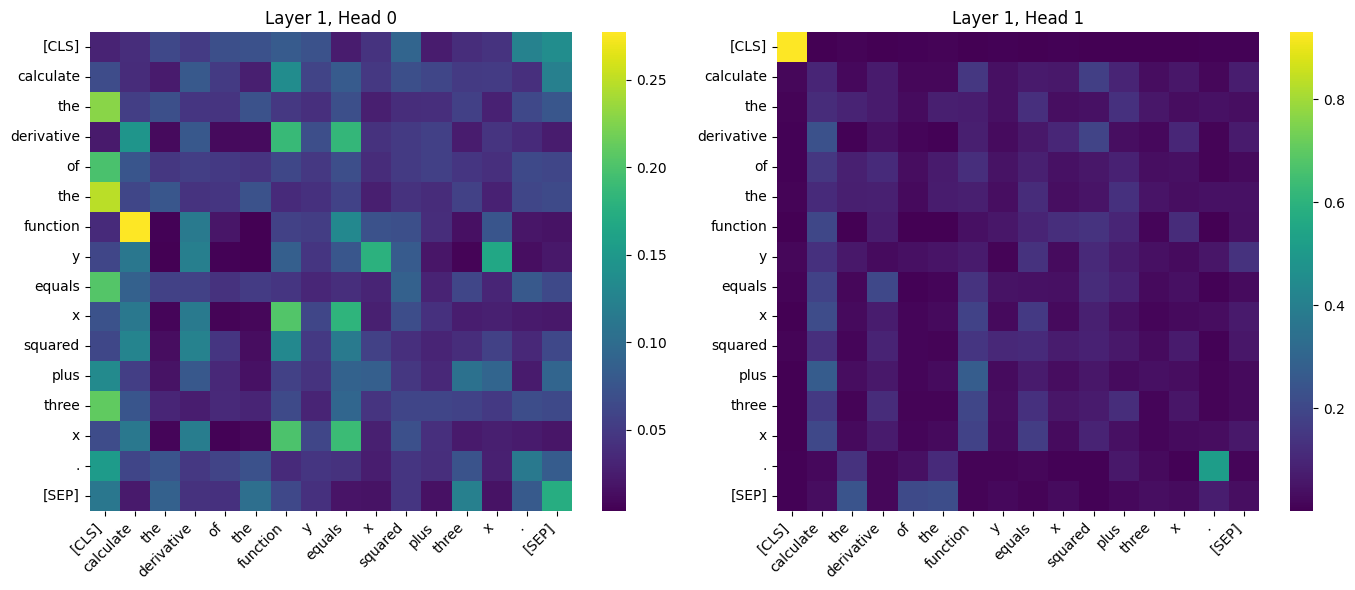

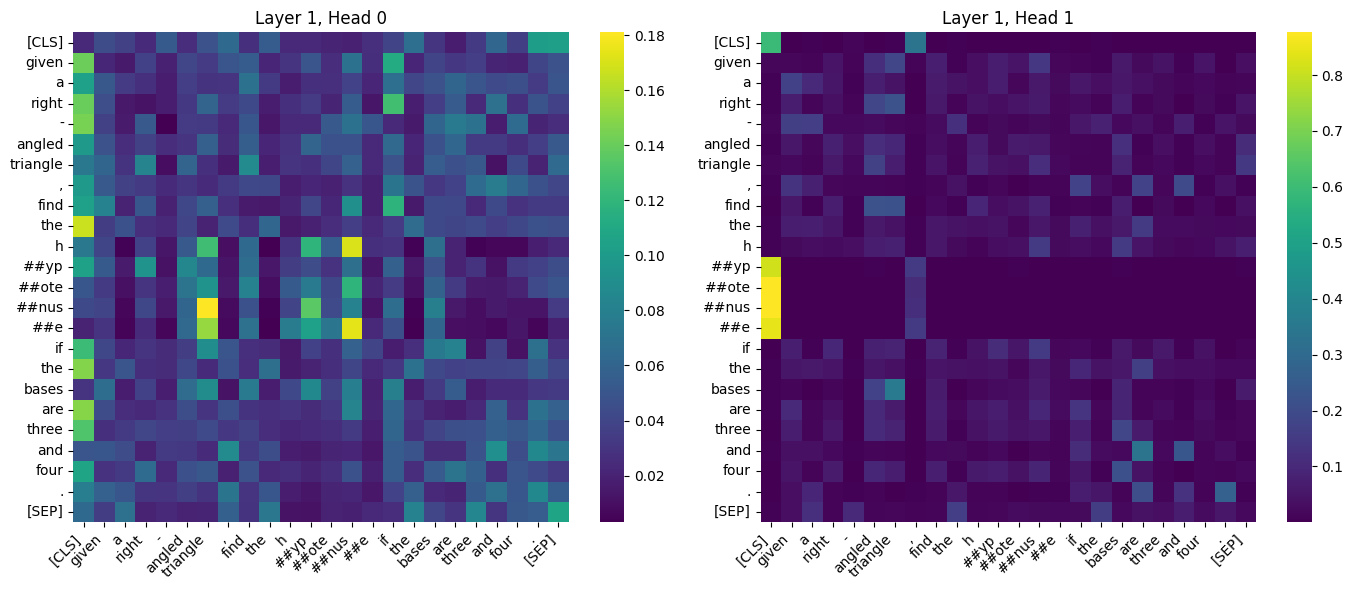

--- MathBERT (BEFORE fine-tuning) ---


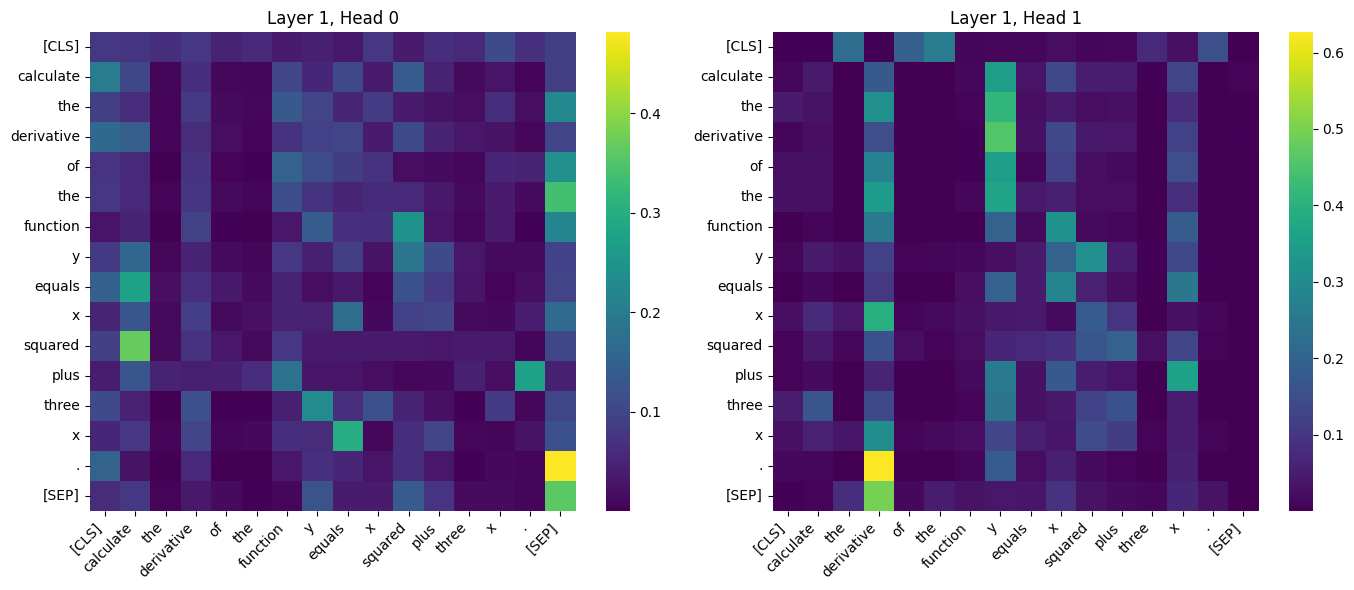

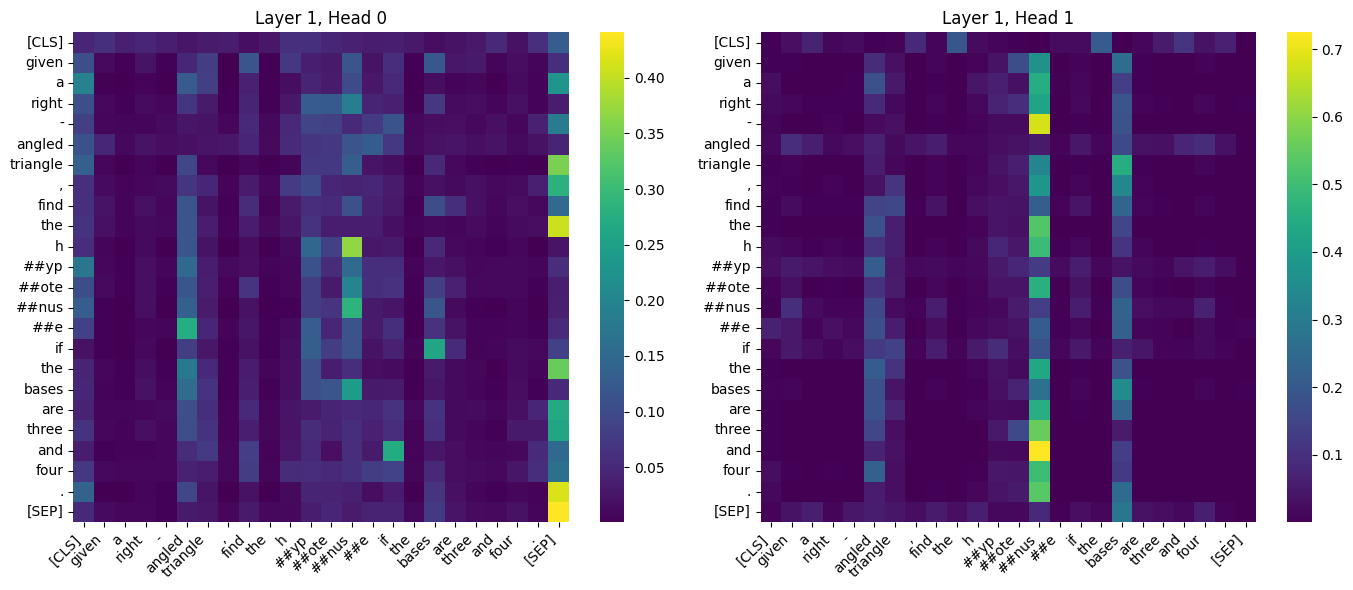

In [13]:

sample_english_texts = [
    "Calculate the derivative of the function y equals x squared plus three x.",
    "Given a right-angled triangle, find the hypotenuse if the bases are three and four.",
]

fresh_distilbert_model = TransformerClassificationModel(
    model_name_distilbert, num_labels
)
fresh_math_model = TransformerClassificationModel(model_name_math, num_labels)

print("--- DistilBERT (BEFORE fine-tuning) ---")
for text in sample_english_texts:
    draw_first_layer_attention_maps(
        [0, 1], text, fresh_distilbert_model, model_name_distilbert
    )

print("--- MathBERT (BEFORE fine-tuning) ---")
for text in sample_english_texts:
    draw_first_layer_attention_maps(
        [0, 1], text, fresh_math_model, model_name_math
    )


### Задание 8 (1 балл)

Сделайте то же самое для дообученных моделей. Изменились ли карты внимания и связи, которые они улавливают? Почему?

--- DistilBERT (AFTER full fine-tuning) ---


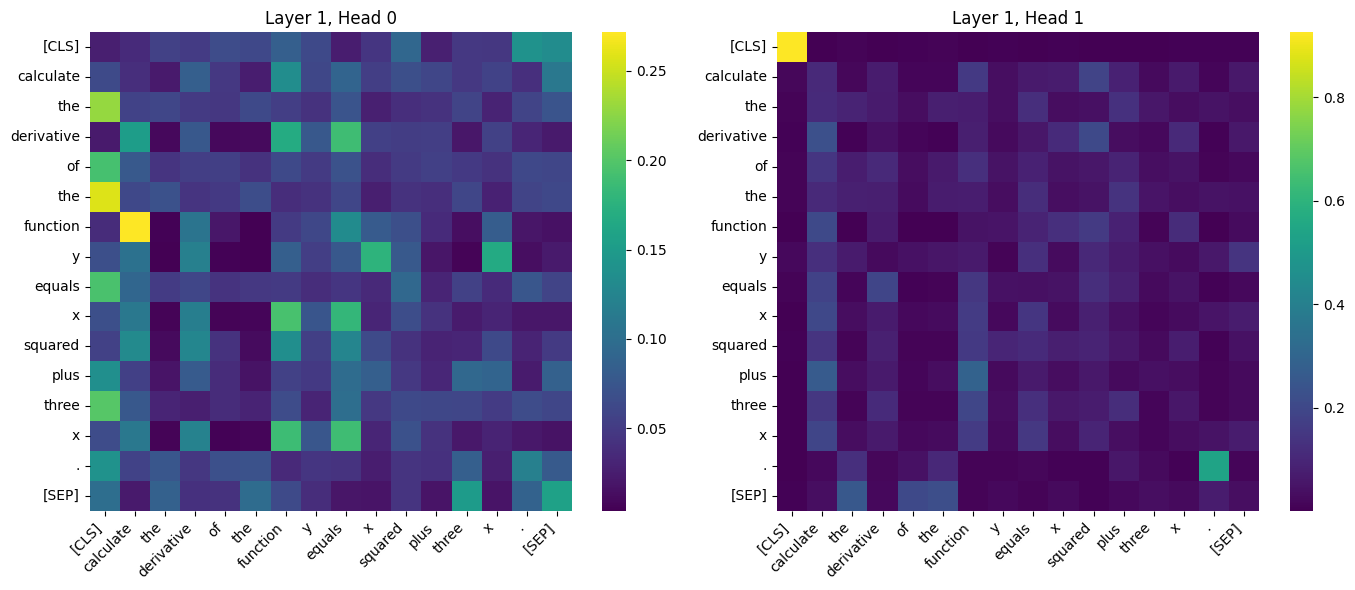

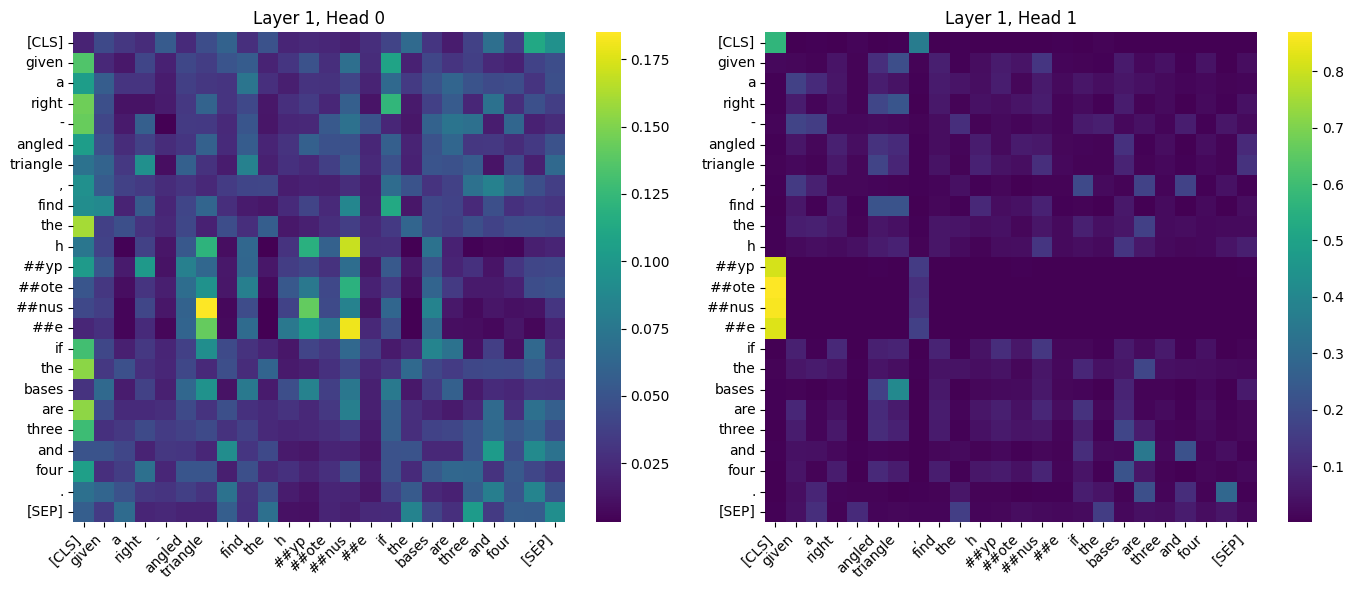

--- MathBERT (AFTER full fine-tuning) ---


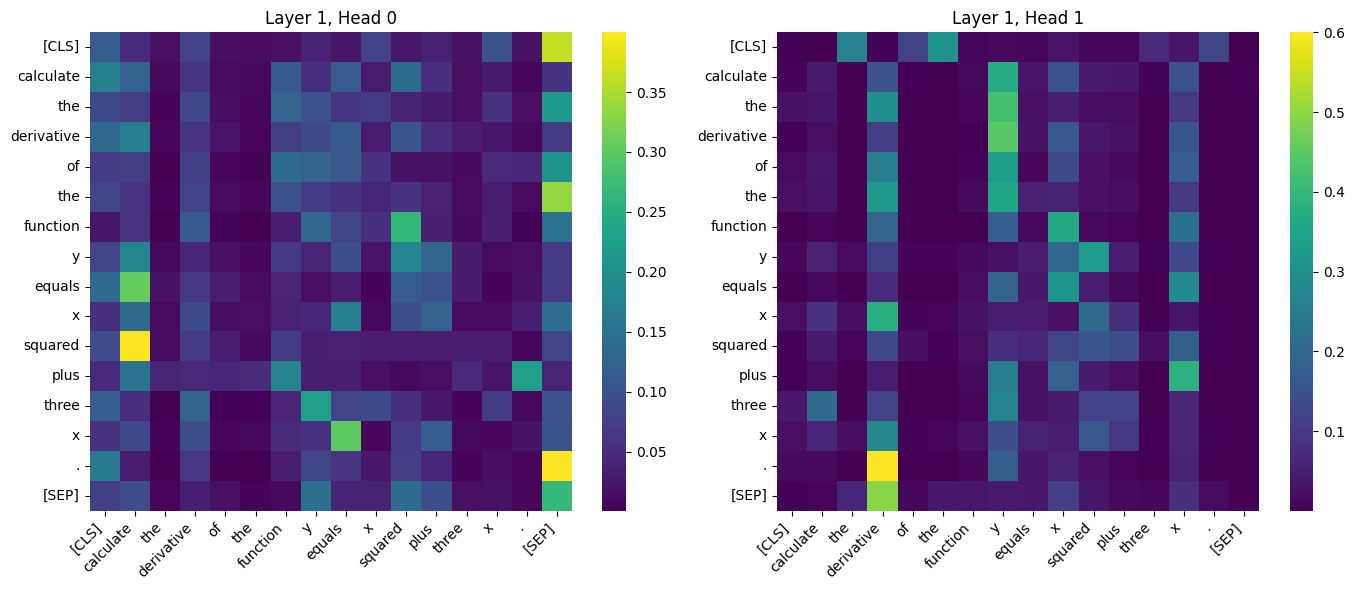

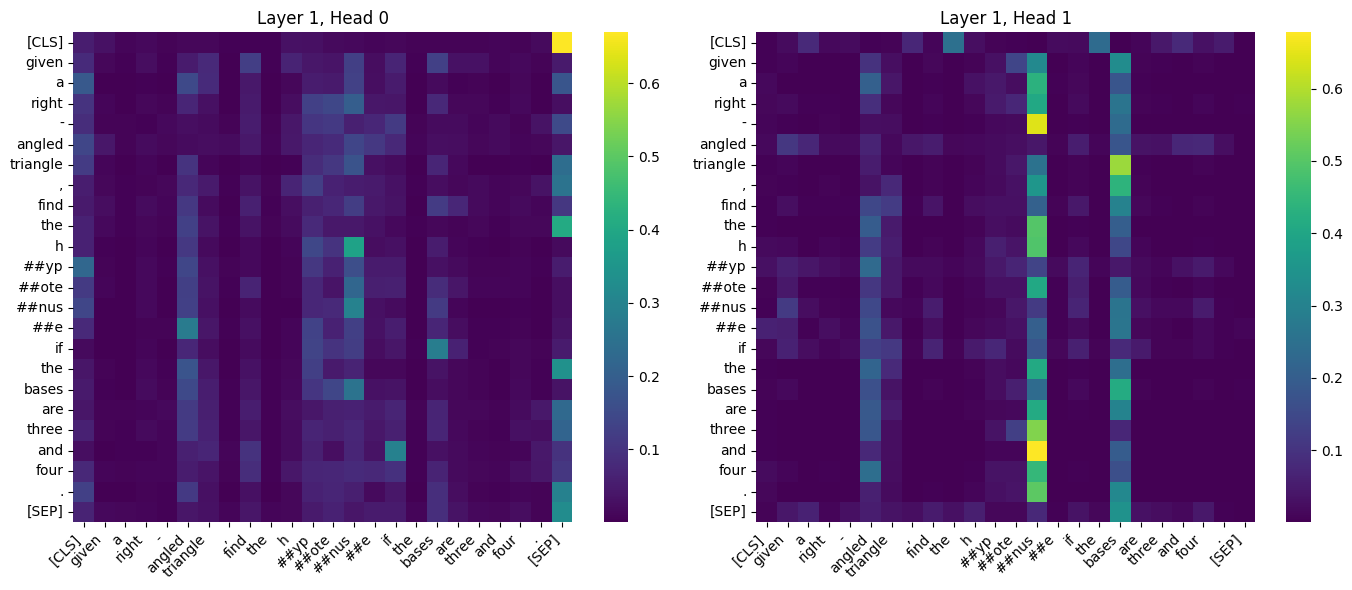

In [14]:
print("--- DistilBERT (AFTER full fine-tuning) ---")
for text in sample_english_texts:
    draw_first_layer_attention_maps(
        [0, 1], text, distilbert_full_finetuned, model_name_distilbert
    )

print("--- MathBERT (AFTER full fine-tuning) ---")
for text in sample_english_texts:
    draw_first_layer_attention_maps(
        [0, 1], text, mathbert_full, model_name_math
    )


# Вывод

Эксперименты подтвердили, что полное размораживание слоев (Full Fine-Tuning) значительно превосходит метод с замороженным бэкбоном. Заморозка весов сильно ограничивает способность модели адаптироваться, в то время как полное дообучение позволяет внутренним слоям перестроиться под специфику датасета, что приводит к быстрому падению лосса и высокой точности.

 Специализированная модель tbs17/MathBERT показала результаты значительно выше, чем модель общего назначения distilbert-base-uncased. За счет того, что MathBERT изначально обучался на научных статьях и формулах, его токенизатор корректно обрабатывает математические термины и операторы, не разбивая их на бессмысленные подтокены и не превращая в неизвестные слова ([UNK]).

Визуализация карт внимания первого слоя наглядно показала, как меняется логика модели. До обучения трансформеры используют общие языковые паттерны (уделяют внимание соседним словам или техническим токенам). После дообучения механизм внимания становится высококонтрастным и сфокусированным: классификационный токен [CLS] начинает напрямую смотреть на ключевые слова-триггеры (такие как 'derivative', 'triangle', 'hypotenuse'), полностью игнорируя грамматический шум (артикли, предлоги и союзы).
